In [34]:
import pandas as pd
import seaborn as sns
import numpy as np 
from pathlib import Path

# Dataset path
DATA_PATH = Path("C:/Users/ASUS/Documents/GitHub/AWS_Project/data/raw/retail_customer_churn_100k (1).csv")

def load_dataset(path=DATA_PATH):
    """Load and return the customer churn dataset."""
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {path.resolve()}"
        )

    df = pd.read_csv(path)
    return df


if __name__ == "__main__":
    df = load_dataset()

    print("\n========== DATASET OVERVIEW ==========")
    print("Shape:", df.shape)
    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    print("\n========== FIRST 5 RECORDS ==========")
    print(df.head())

    print("\n========== COLUMN NAMES ==========")
    print(df.columns.tolist())

    print("\n========== DATA TYPES ==========")
    print(df.dtypes)

    print("\n========== STATISTICAL SUMMARY ==========")
    print(df.describe(include="all").T)



========== DATASET OVERVIEW ==========
Shape: (100000, 18)
Number of rows: 100000
Number of columns: 18

========== FIRST 5 RECORDS ==========
  customer_id age_group gender region customer_segment preferred_channel  \
0     C000001     18-24  Other  North            Loyal            Online   
1     C000002     25-34  Other  South              New        Mobile App   
2     C000003       55+  Other  North              VIP            Online   
3     C000004     18-24   Male  North        Returning        Mobile App   
4     C000005       55+  Other  North        Returning        Mobile App   

   purchase_frequency  avg_order_value  total_spent  recency_days  \
0                   5           381.27      2108.80           189   
1                  12           376.65      3843.06           277   
2                   5            37.73       224.65           271   
3                  12           191.19      1960.79            89   
4                   2           279.64       594.79   

In [35]:
print("Rows and columns:", df.shape)

# Column names and data types
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Missing Values": df.isnull().sum().values,
        "Unique Values": df.nunique(dropna=False).values
    })
)

# Statistical summary
display(df.describe(include="all").T)


Rows and columns: (100000, 18)


,Column,Data Type,Missing Values,Unique Values
0,customer_id,object,0,100000
1,age_group,object,0,5
2,gender,object,0,3
3,region,object,0,5
4,customer_segment,object,0,4
5,preferred_channel,object,0,3
6,purchase_frequency,int64,0,9
7,avg_order_value,float64,0,35250
8,total_spent,float64,0,86590
9,recency_days,int64,0,364


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,100000,100000,C000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_group,100000,5,35-44,20109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,100000,3,Male,33434,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,100000,5,East,20240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,100000,4,New,25113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
preferred_channel,100000,3,Online,33430,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purchase_frequency,100000.0,NaN,NaN,NaN,11.80222,14.368458,1.0,2.0,8.0,12.0,60.0
avg_order_value,100000.0,NaN,NaN,NaN,209.704723,109.710192,20.03,114.61,209.485,304.75,400.0
total_spent,100000.0,NaN,NaN,NaN,2543.890827,3790.838484,17.87,381.3175,1089.18,2952.1725,28444.24
recency_days,100000.0,NaN,NaN,NaN,182.74054,105.123047,1.0,92.0,182.0,274.0,364.0


In [36]:
import matplotlib.pyplot as plt
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    missing.plot(
        kind="bar",
        figsize=(10, 5),
        title="Missing Values by Column"
    )
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


No missing values found.


### Visualize churn distribution

In [37]:

TARGET = "Churn"

if TARGET not in df.columns:
    print("Update TARGET to match your actual target column.")
else:
    display(
        df[TARGET]
        .value_counts(dropna=False)
        .rename_axis(TARGET)
        .to_frame("Customer Count")
    )

    sns.countplot(data=df, x=TARGET)
    plt.title("Customer Churn Distribution")
    plt.xlabel("Churn Status")
    plt.ylabel("Number of Customers")
    plt.tight_layout()
    plt.show()


Update TARGET to match your actual target column.


### Identify numerical and categorical columns

In [38]:
import numpy as np
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)

print("\nNumerical feature count:", len(numeric_cols))
print("Categorical feature count:", len(categorical_cols))


Numerical columns: ['purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score', 'churn_flag']

Categorical columns: ['customer_id', 'age_group', 'gender', 'region', 'customer_segment', 'preferred_channel', 'churn_risk']

Numerical feature count: 11
Categorical feature count: 7


### Numerical distributions

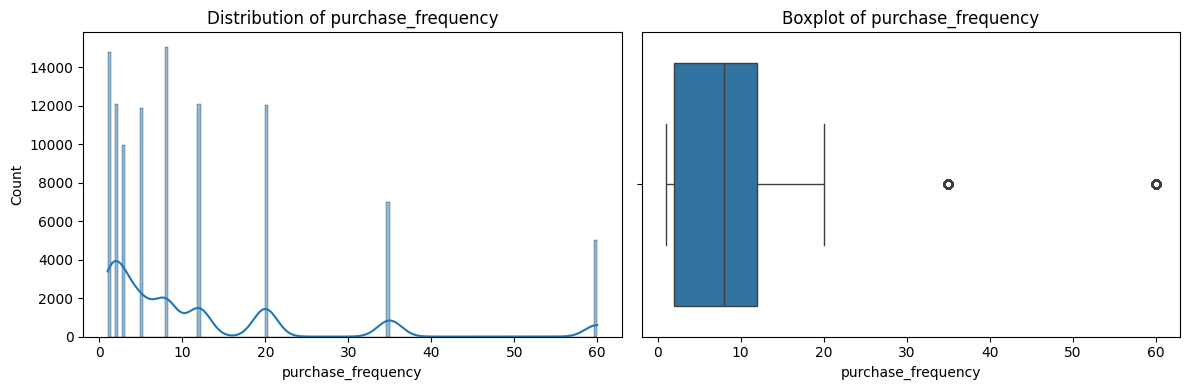

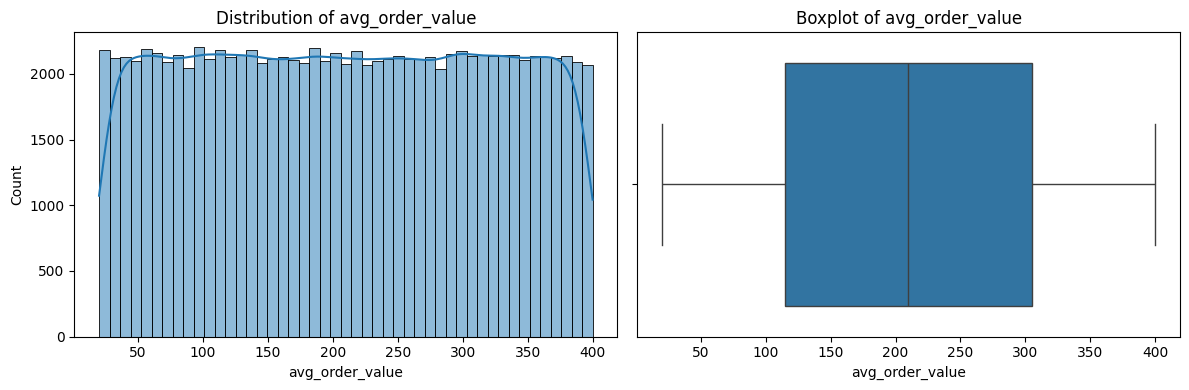

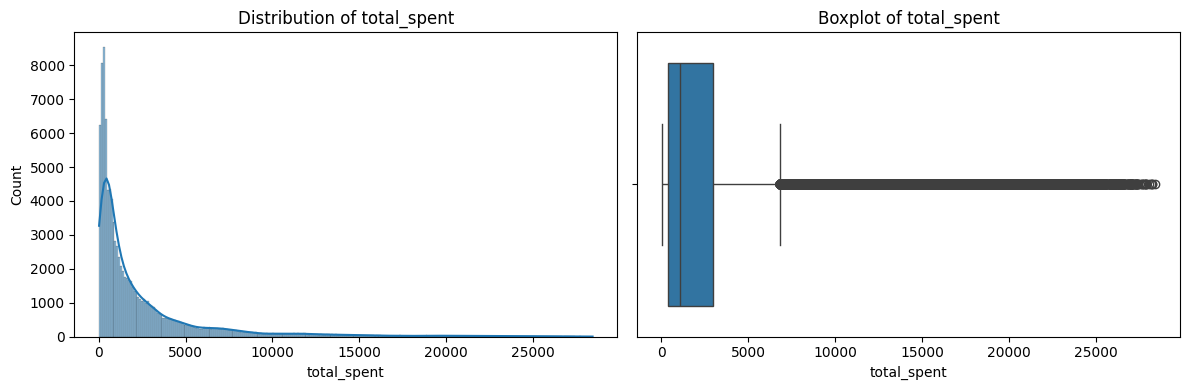

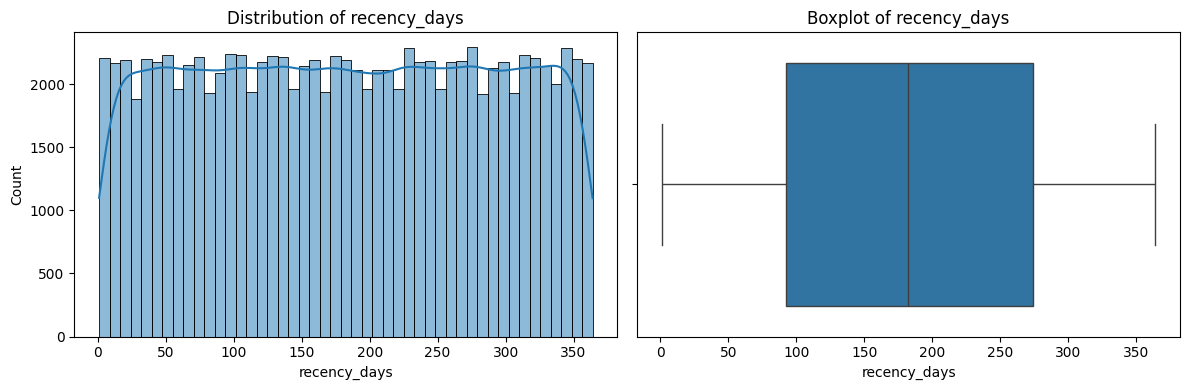

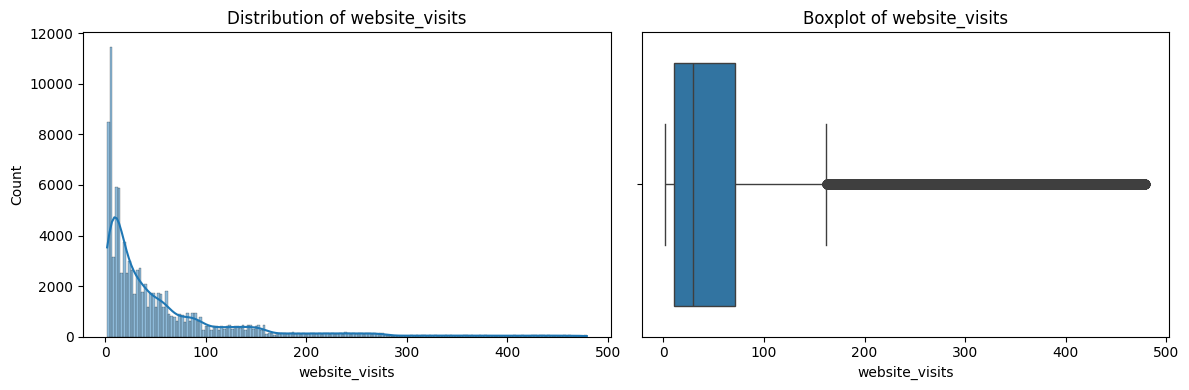

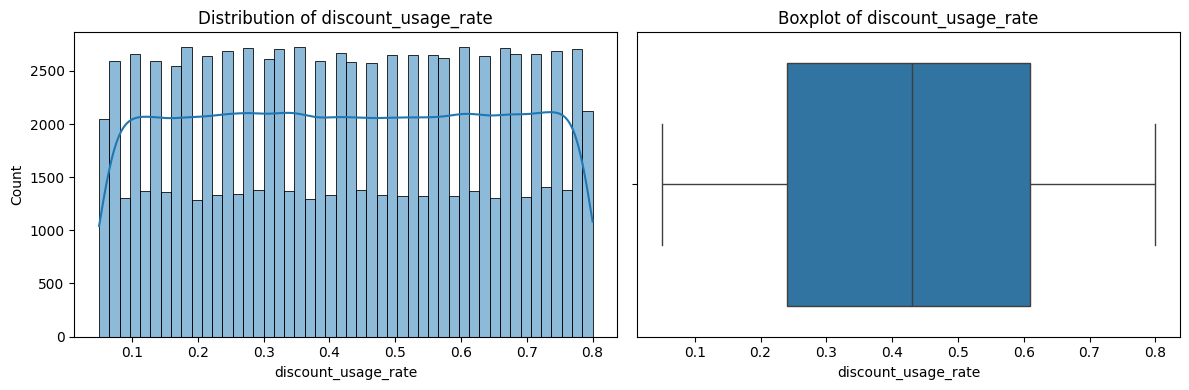

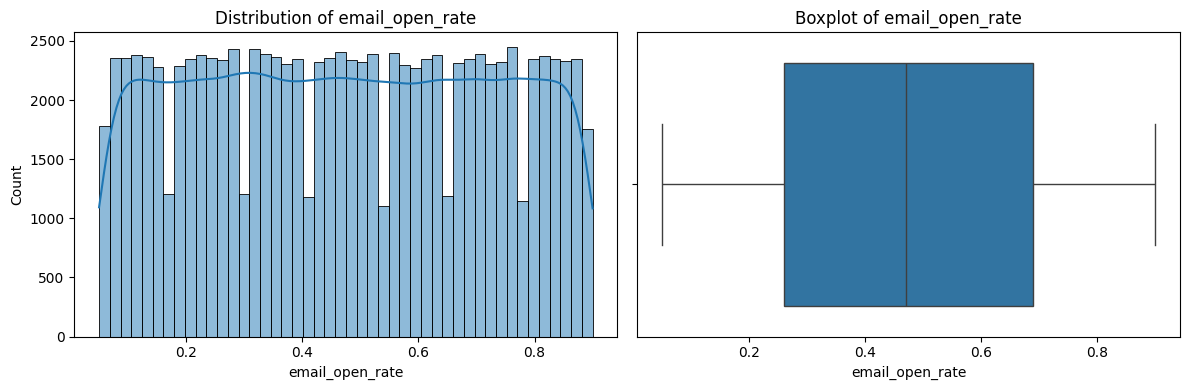

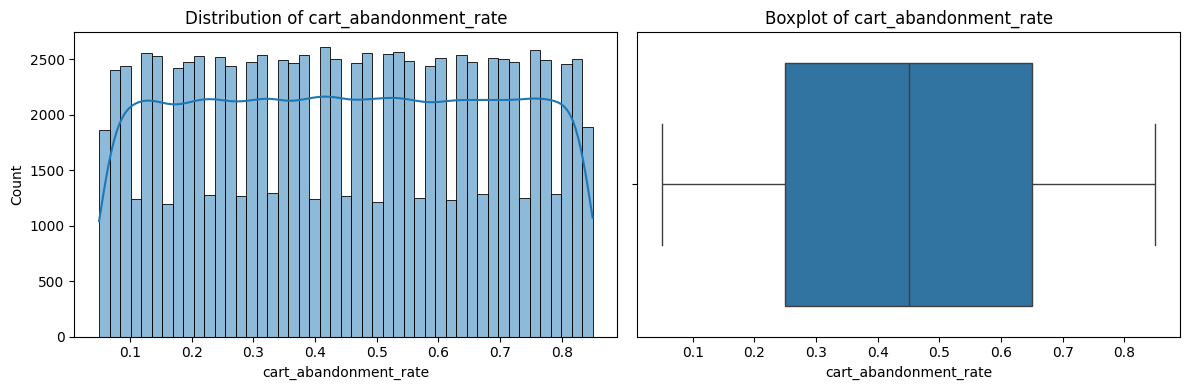

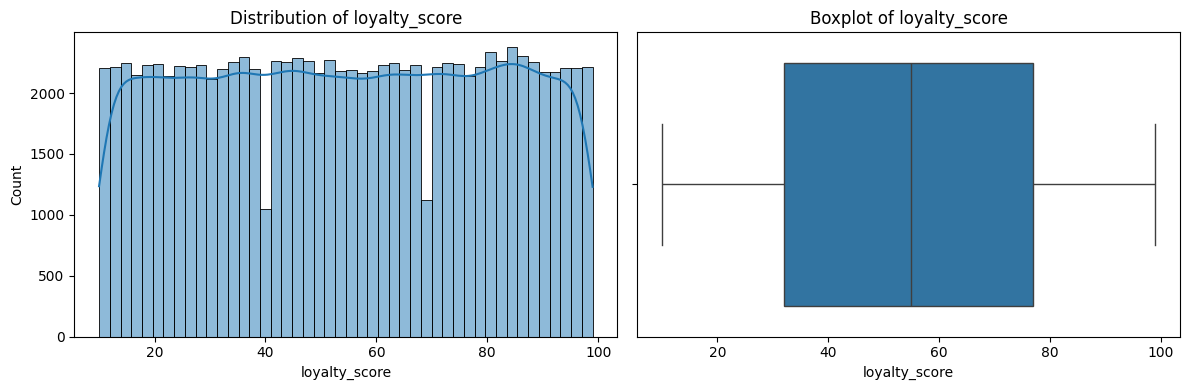

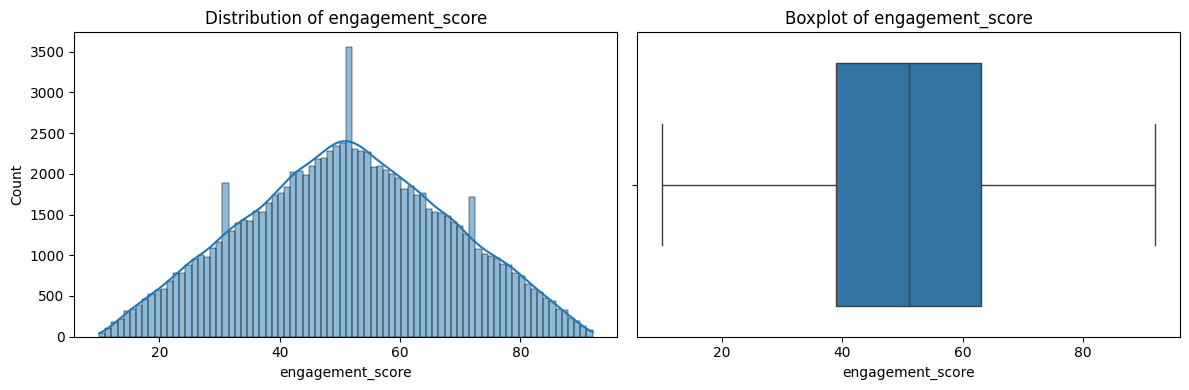

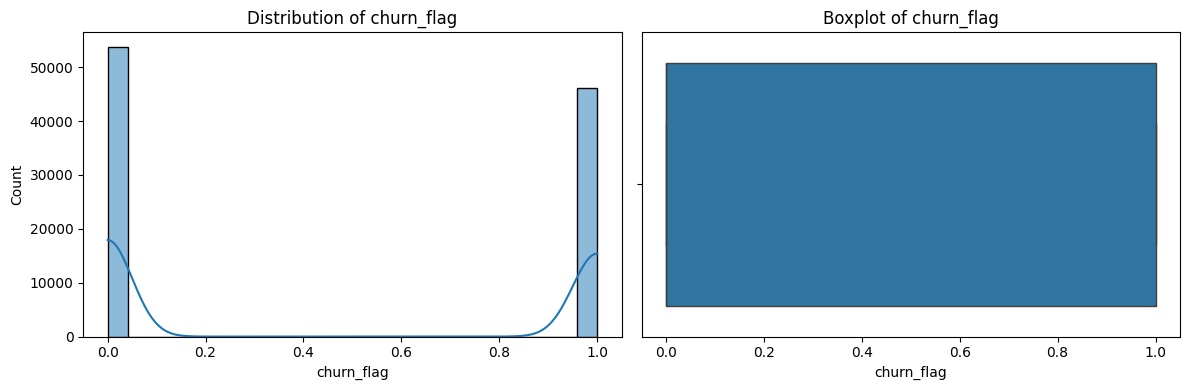

In [39]:
import seaborn as sns
for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(data=df, x=col, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")

    sns.boxplot(data=df, x=col, ax=axes[1])
    axes[1].set_title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()


### Categorical distributions

Skipping customer_id: too many unique categories


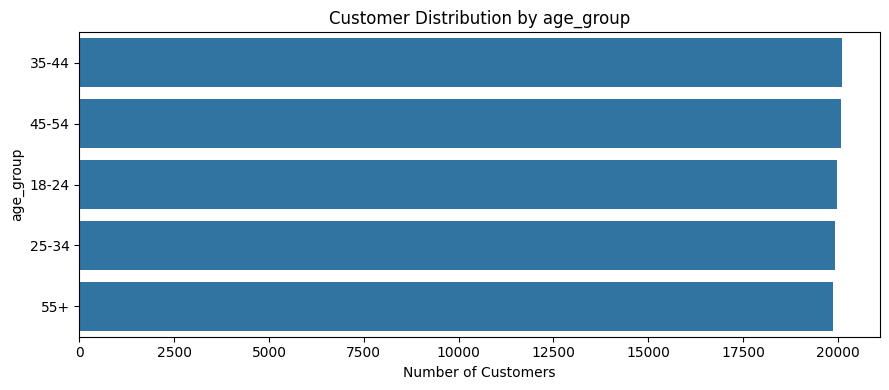

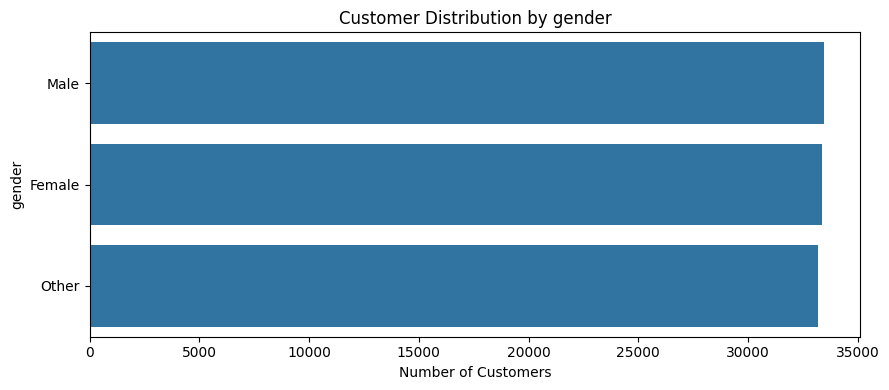

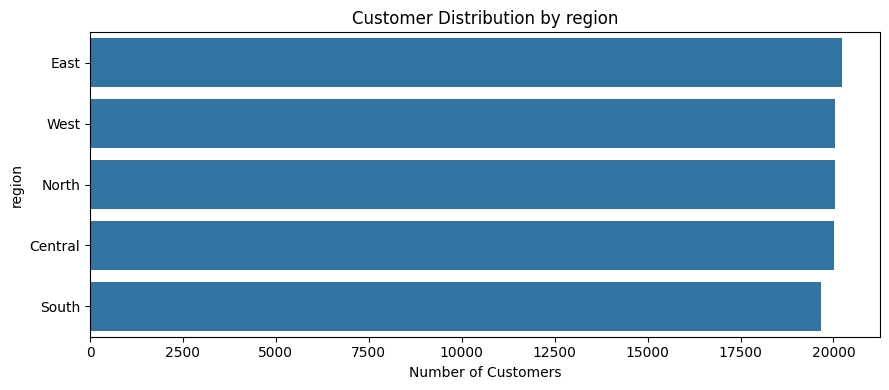

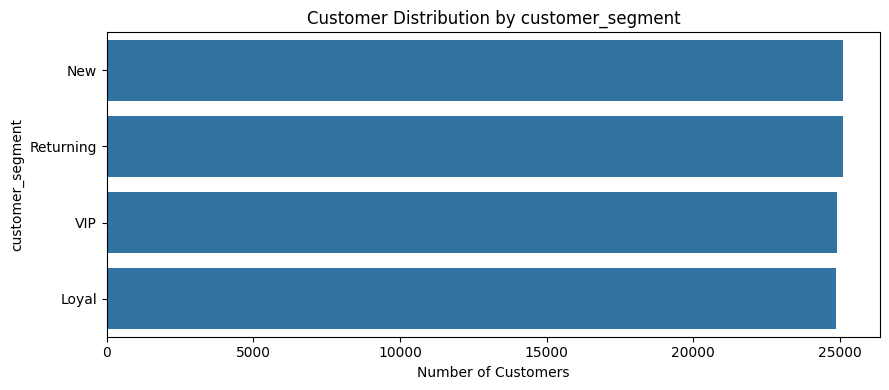

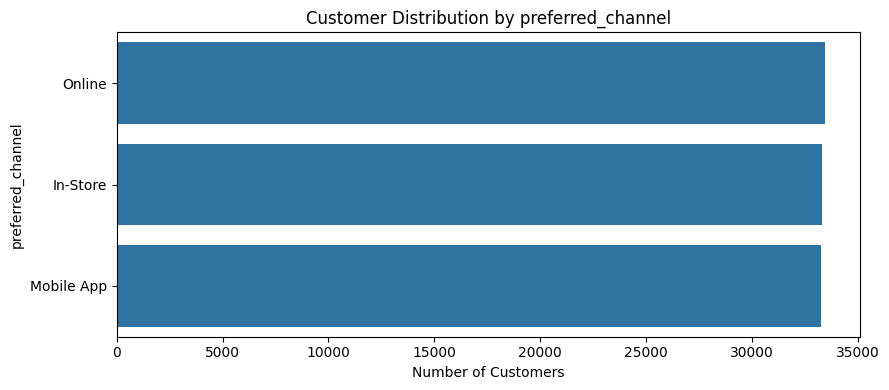

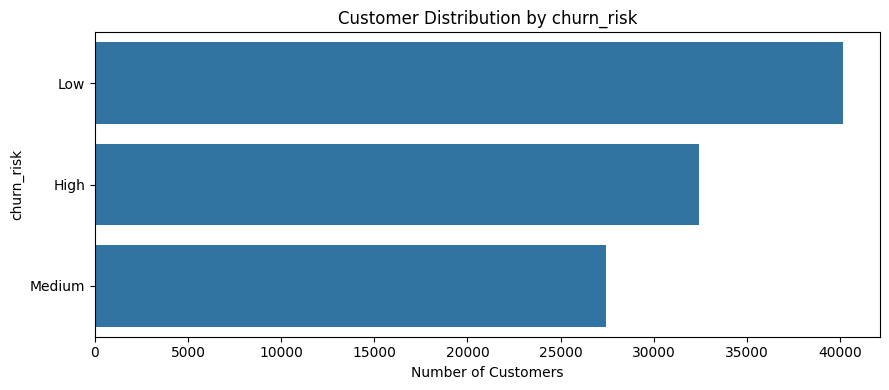

In [40]:

# Bar charts for categorical features

for col in categorical_cols:
    if df[col].nunique(dropna=False) > 20:
        print(f"Skipping {col}: too many unique categories")
        continue

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=df,
        y=col,
        order=df[col].value_counts().index
    )

    plt.title(f"Customer Distribution by {col}")
    plt.xlabel("Number of Customers")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


### Advanced data quality and outlier analysis

In [41]:

outlier_results = []

for col in numeric_cols:
    values = df[col].dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_bound) | (values > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outlier_count),
        "Outlier Percentage": round(
            outlier_count / len(values) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

display(
    outlier_df.sort_values(
        "Outlier Percentage",
        ascending=False
    )
)


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,purchase_frequency,-13.000,27.000,12011,12.01
2,total_spent,-3474.965,6808.455,9738,9.74
4,website_visits,-81.500,162.500,8251,8.25
1,avg_order_value,-170.600,589.960,0,0.00
3,recency_days,-181.000,547.000,0,0.00
5,discount_usage_rate,-0.315,1.165,0,0.00
6,email_open_rate,-0.385,1.335,0,0.00
7,cart_abandonment_rate,-0.350,1.250,0,0.00
8,loyalty_score,-35.500,144.500,0,0.00
9,engagement_score,3.000,99.000,0,0.00


### Check duplicates and empty strings

In [42]:
print("Duplicate rows:", df.duplicated().sum())

empty_string_report = {}

for col in df.select_dtypes(include="object").columns:
    count = df[col].astype("string").str.strip().eq("").sum()

    if count > 0:
        empty_string_report[col] = int(count)

print("\nEmpty strings by column:")
print(empty_string_report if empty_string_report else "None found")


Duplicate rows: 0

Empty strings by column:
None found


### Correlation heatmap

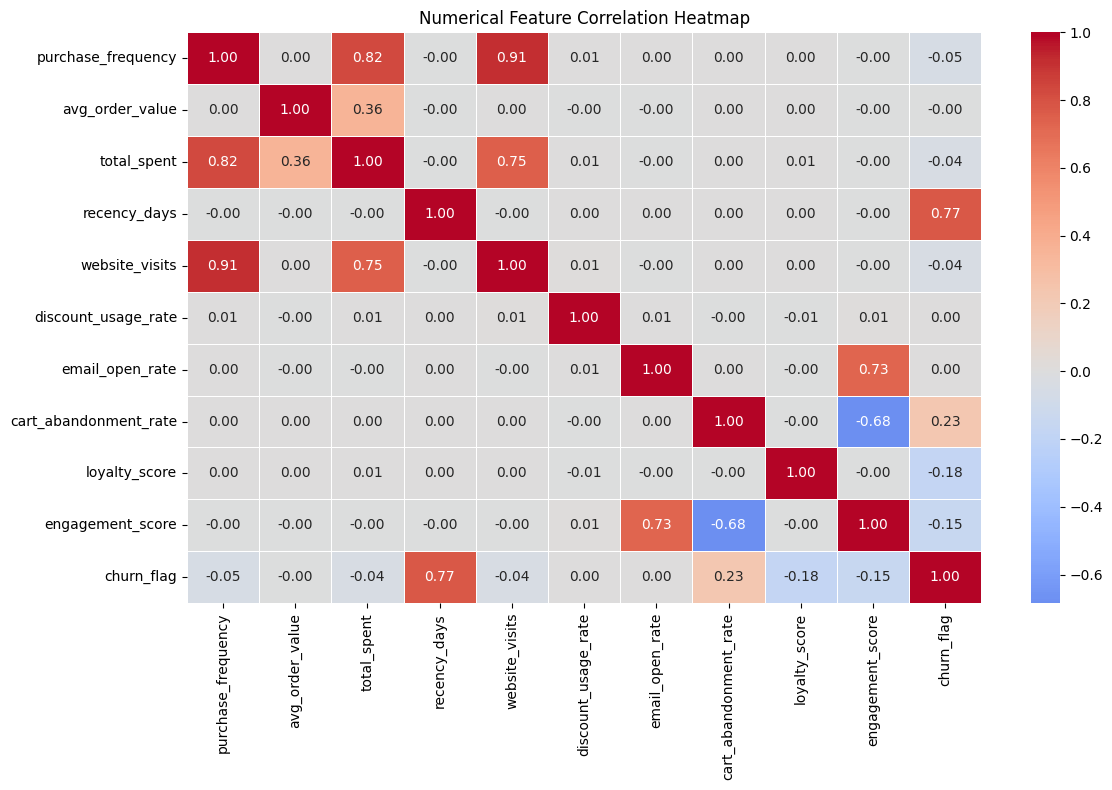

In [43]:
corr_df = df.select_dtypes(include=np.number)

if corr_df.shape[1] >= 2:
    correlation_matrix = corr_df.corr()

    plt.figure(figsize=(12, 8))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5
    )

    plt.title("Numerical Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are needed.")


### **Churn-focused analysis**

In [49]:

# STEP 9.1: Target variable analysis

TARGET = "churn_flag"

print("Target variable:", TARGET)

print("\nChurn flag counts:")
display(df[TARGET].value_counts(dropna=False).to_frame("Customer Count"))

print("\nChurn flag percentages:")
display(
    (
        df[TARGET].value_counts(normalize=True, dropna=False) * 100
    ).round(2).to_frame("Percentage")
)

print("\nUnique values:", df[TARGET].unique())


Target variable: churn_flag

Churn flag counts:


,Customer Count
churn_flag,
0,53776
1,46224



Churn flag percentages:


,Percentage
churn_flag,
0,53.78
1,46.22



Unique values: [1 0]


### Churn rates by categorical feature

In [47]:
TARGET = "churn_flag"

print("Target variable:", TARGET)

print("\nChurn flag counts:")
display(df[TARGET].value_counts(dropna=False).to_frame("Customer Count"))

print("\nChurn flag percentages:")
display(
    (
        df[TARGET].value_counts(normalize=True, dropna=False) * 100
    ).round(2).to_frame("Percentage")
)

print("\nUnique values:", df[TARGET].unique())


Check target labels and update the churn-positive label.


### Calculate churn rates by customer category

In [51]:
TARGET = "churn_flag"

CHURN_VALUE = 1

analysis_df = df.dropna(subset=[TARGET]).copy()

# Convert target values into a consistent binary flag
if set(analysis_df[TARGET].unique()).issubset({0, 1}):
    analysis_df["churn_binary"] = (
        analysis_df[TARGET] == CHURN_VALUE
    ).astype(int)

elif set(analysis_df[TARGET].unique()).issubset({"Yes", "No"}):
    analysis_df["churn_binary"] = (
        analysis_df[TARGET] == "Yes"
    ).astype(int)

else:
    raise ValueError(
        "Unexpected churn_flag values. "
        "Inspect df[TARGET].unique() before continuing."
    )

features = [
    "age_group",
    "gender",
    "region",
    "customer_segment",
    "preferred_channel",
    "purchase_frequency"
]

features = [col for col in features if col in analysis_df.columns]

for feature in features:
    summary = (
        analysis_df.groupby(feature, dropna=False)["churn_binary"]
        .agg(
            Customer_Count="size",
            Churn_Rate="mean"
        )
        .reset_index()
    )

    summary["Churn_Rate_Percent"] = (
        summary["Churn_Rate"] * 100
    ).round(2)

    print(f"\nChurn analysis by {feature}")
    display(
        summary.sort_values(
            "Churn_Rate_Percent",
            ascending=False
        )
    )



Churn analysis by age_group


,age_group,Customer_Count,Churn_Rate,Churn_Rate_Percent
4,55+,19882,0.465094,46.51
2,35-44,20109,0.463673,46.37
0,18-24,19987,0.462401,46.24
3,45-54,20093,0.461106,46.11
1,25-34,19929,0.458929,45.89



Churn analysis by gender


,gender,Customer_Count,Churn_Rate,Churn_Rate_Percent
1,Male,33434,0.463271,46.33
0,Female,33367,0.462703,46.27
2,Other,33199,0.460737,46.07



Churn analysis by region


...

,customer_segment,Customer_Count,Churn_Rate,Churn_Rate_Percent
3,VIP,24906,0.466715,46.67
1,New,25113,0.463186,46.32
2,Returning,25106,0.459810,45.98
0,Loyal,24875,0.459256,45.93



Churn analysis by preferred_channel


,preferred_channel,Customer_Count,Churn_Rate,Churn_Rate_Percent
2,Online,33430,0.466647,46.66
0,In-Store,33303,0.462571,46.26
1,Mobile App,33267,0.457480,45.75



Churn analysis by purchase_frequency


,purchase_frequency,Customer_Count,Churn_Rate,Churn_Rate_Percent
0,1,14813,0.485722,48.57
2,3,9988,0.479275,47.93
1,2,12112,0.476965,47.70
3,5,11888,0.474428,47.44
4,8,15069,0.465260,46.53
5,12,12092,0.461628,46.16
6,20,12027,0.448408,44.84
7,35,7003,0.415536,41.55
8,60,5008,0.385184,38.52


###  Visualize churn rates by customer segment

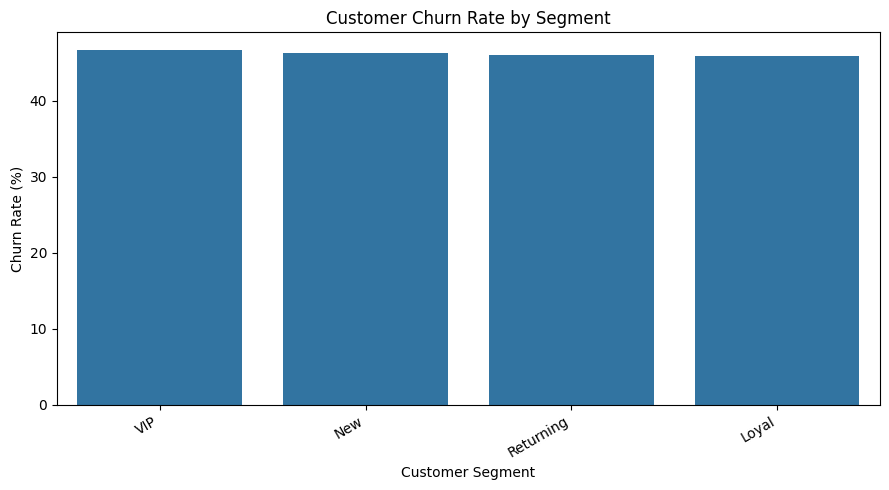

In [52]:

import matplotlib.pyplot as plt
import seaborn as sns

feature = "customer_segment"

if feature in analysis_df.columns:
    plot_data = (
        analysis_df.groupby(feature, dropna=False)["churn_binary"]
        .mean()
        .mul(100)
        .reset_index(name="Churn Rate (%)")
        .sort_values("Churn Rate (%)", ascending=False)
    )

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=plot_data,
        x=feature,
        y="Churn Rate (%)"
    )

    plt.title("Customer Churn Rate by Segment")
    plt.xlabel("Customer Segment")
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print(f"Column '{feature}' not found.")


In [54]:
print("Churn flag counts:")
print(df["churn_flag"].value_counts(dropna=False))

print("\nChurn flag percentages:")
print(
    (df["churn_flag"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

print("\nUnique values:")
print(df["churn_flag"].unique())


Churn flag counts:
churn_flag
0    53776
1    46224
Name: count, dtype: int64

Churn flag percentages:
churn_flag
0    53.78
1    46.22
Name: proportion, dtype: float64

Unique values:
[1 0]


### Check churn rates manually

In [55]:
numeric_features = [
    "avg_order_value",
    "total_spent",
    "recency_days",
    "website_visits",
    "discount_usage_rate",
    "email_open_rate",
    "cart_abandonment_rate",
    "loyalty_score",
    "engagement_score"
]

numeric_features = [
    col for col in numeric_features
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

display(
    df.groupby("churn_flag")[numeric_features]
      .mean()
      .T
      .rename(columns={0: "Flag 0", 1: "Flag 1"})
)


churn_flag,Flag 0,Flag 1
avg_order_value,210.145141,209.192351
total_spent,2692.556727,2370.936140
recency_days,107.301993,270.504110
website_visits,61.745649,54.776804
discount_usage_rate,0.425870,0.426681
email_open_rate,0.473958,0.475171
cart_abandonment_rate,0.402234,0.507693
loyalty_score,58.834926,49.709588
engagement_score,53.586209,48.373875


In [53]:
print(df["churn_flag"].unique())
print(df["churn_flag"].dtype)

[1 0]
int64


### ***Advanced correlation analysis***

In [57]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

TARGET = "churn_flag"

numeric_features = [
    "avg_order_value",
    "total_spent",
    "recency_days",
    "website_visits",
    "discount_usage_rate",
    "email_open_rate",
    "cart_abandonment_rate",
    "loyalty_score",
    "engagement_score"
]

numeric_features = [
    col for col in numeric_features
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
]

print("Numerical features selected:")
print(numeric_features)

print("\nMissing values:")
display(df[numeric_features].isnull().sum().to_frame("Missing Count"))


Numerical features selected:
['avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score']

Missing values:


,Missing Count
avg_order_value,0
total_spent,0
recency_days,0
website_visits,0
discount_usage_rate,0
email_open_rate,0
cart_abandonment_rate,0
loyalty_score,0
engagement_score,0


**Compare group statistics**

In [59]:

TARGET = "churn_flag"

print("Churn target values:")
print(df[TARGET].value_counts(dropna=False))

group_summary = (
    df.groupby(TARGET)[numeric_features]
      .agg(["mean", "median", "std"])
      .round(3)
)

display(group_summary)


Churn target values:
churn_flag
0    53776
1    46224
Name: count, dtype: int64


avg_order_value                   total_spent                      \
                      mean   median      std        mean    median       std   
churn_flag                                                                     
0                  210.145  210.665  109.464    2692.557  1156.685  3961.635   
1                  209.192  208.345  109.995    2370.936  1017.935  3574.173   

           recency_days                website_visits  ... email_open_rate  \
                   mean median     std           mean  ...             std   
churn_flag                                             ...                   
0               107.302  100.0  69.553         61.746  ...           0.246   
1               270.504  279.0  62.897         54.777  ...           0.245   

           cart_abandonment_rate               loyalty_score                 \
                            mean median    std          mean median     std   
churn_flag                                                                    
0                          0.402   0.38  0.226        58.835   61.0  25.628   
1                          0.508   0.53  0.223        49.710   47.0  25.479   

           engagement_score                 
                       mean median     std  
churn_flag                                  
0                    53.586   53.5  16.692  
1                    48.374   48.5  16.552  

[2 rows x 27 columns]

**Plot feature comparisons**

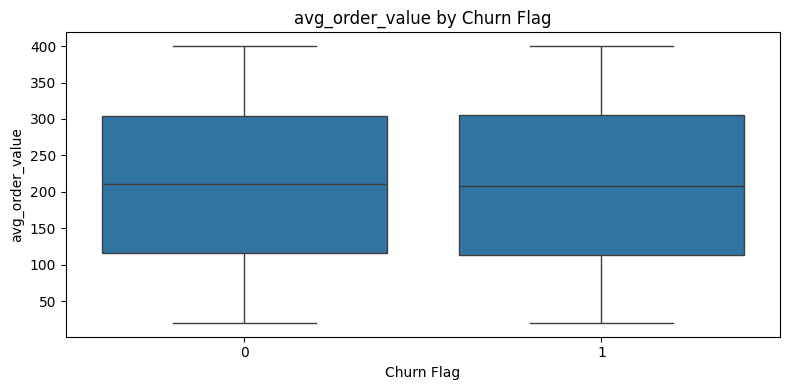

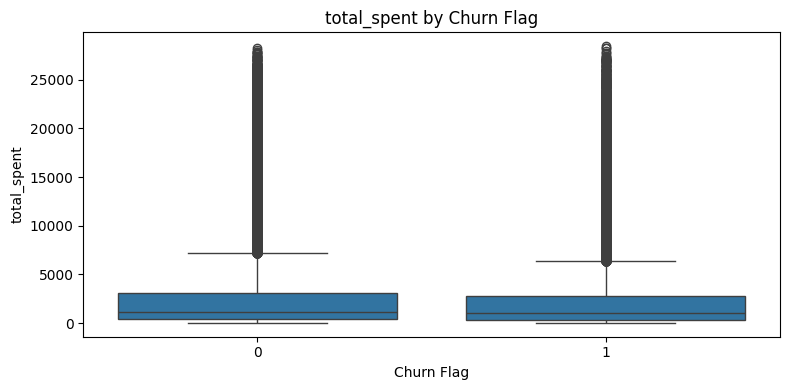

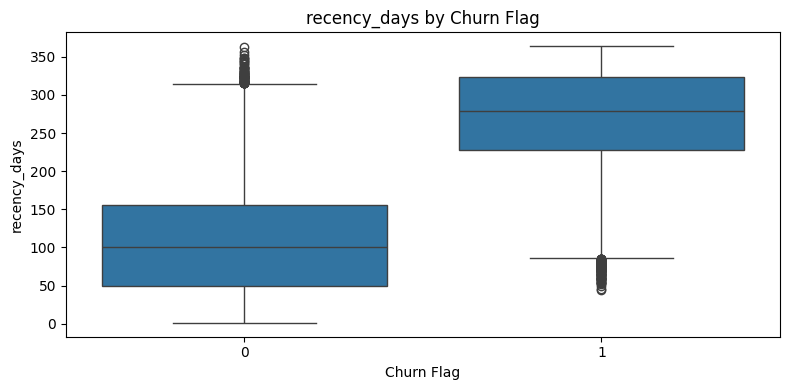

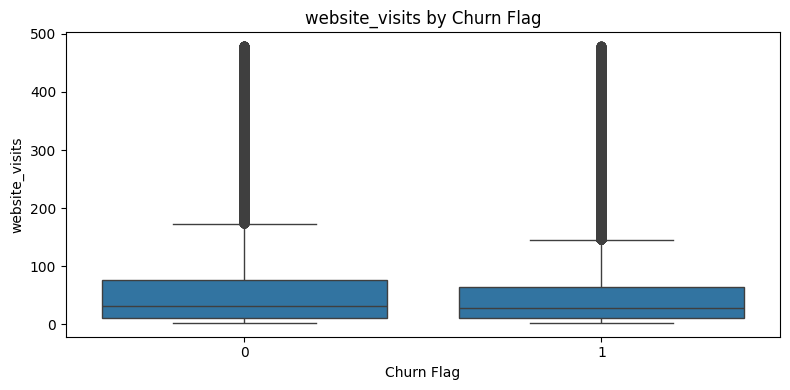

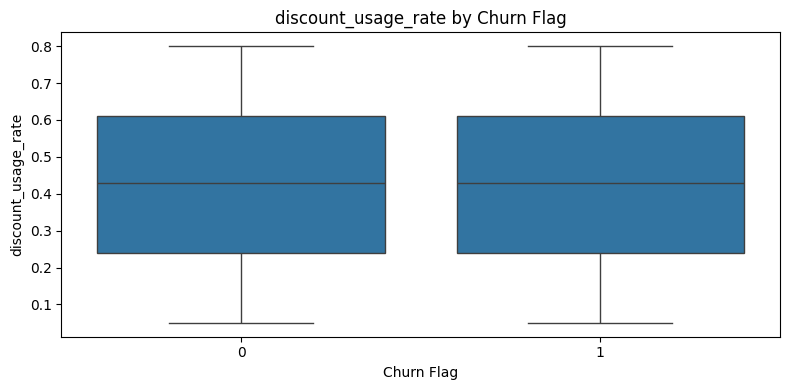

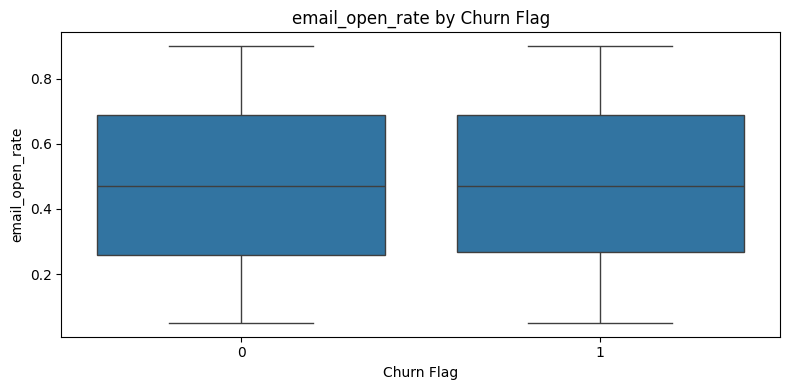

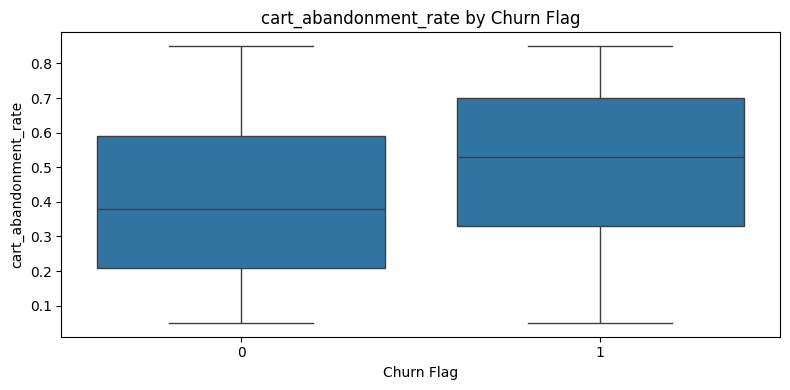

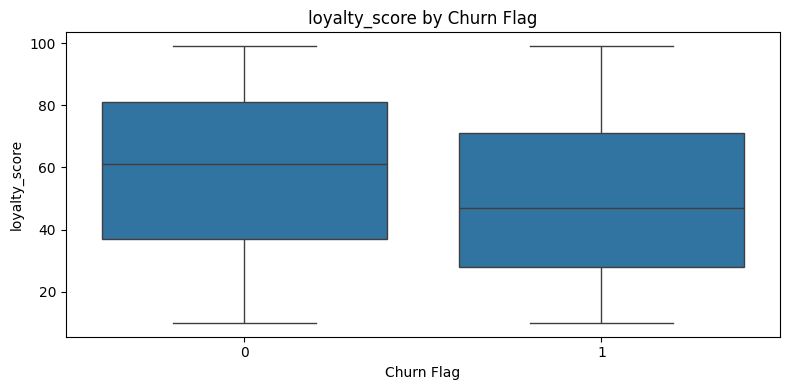

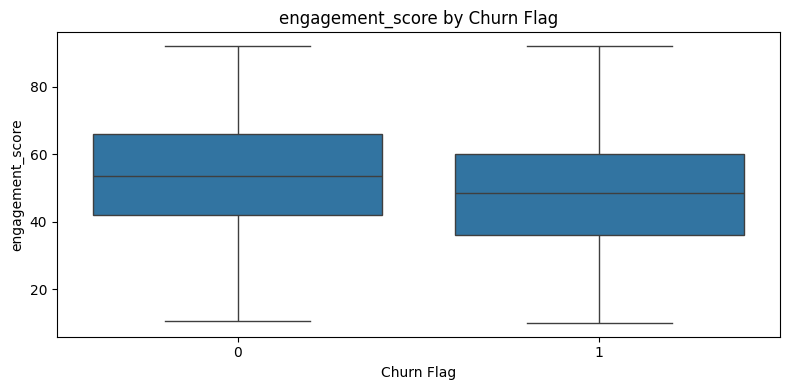

In [60]:

for feature in numeric_features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=feature
    )

    plt.title(f"{feature} by Churn Flag")
    plt.xlabel("Churn Flag")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


**Run statistical tests**

In [62]:

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

TARGET = "churn_flag"

# Verify that there are exactly two non-missing target classes
target_values = df[TARGET].dropna().unique()

if len(target_values) != 2:
    raise ValueError(
        f"Expected two target classes; found {target_values}"
    )

class_0, class_1 = sorted(target_values, key=str)

results = []

for feature in numeric_features:
    group_0 = df.loc[
        df[TARGET] == class_0, feature
    ].dropna()

    group_1 = df.loc[
        df[TARGET] == class_1, feature
    ].dropna()

    if len(group_0) < 2 or len(group_1) < 2:
        continue

    statistic, p_value = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )

    results.append({
        "Feature": feature,
        f"Median ({class_0})": group_0.median(),
        f"Median ({class_1})": group_1.median(),
        "U Statistic": statistic,
        "P Value": p_value
    })

test_results = pd.DataFrame(results)

if not test_results.empty:
    # Correct for multiple comparisons
    test_results["Adjusted P Value"] = multipletests(
        test_results["P Value"],
        method="fdr_bh"
    )[1]

    test_results["Significant (5%)"] = (
        test_results["Adjusted P Value"] < 0.05
    )

    display(
        test_results.sort_values("Adjusted P Value")
    )
else:
    print("Insufficient data to perform statistical tests.")


,Feature,Median (0),Median (1),U Statistic,P Value,Adjusted P Value,Significant (5%)
2,recency_days,100.000,279.000,1.289815e+08,0.000000e+00,0.000000e+00,True
7,loyalty_score,61.000,47.000,1.495103e+09,0.000000e+00,0.000000e+00,True
6,cart_abandonment_rate,0.380,0.530,9.145842e+08,0.000000e+00,0.000000e+00,True
8,engagement_score,53.500,48.500,1.461709e+09,0.000000e+00,0.000000e+00,True
3,website_visits,31.000,27.000,1.301229e+09,1.199290e-37,2.158721e-37,True
1,total_spent,1156.685,1017.935,1.299974e+09,4.157569e-36,6.236354e-36,True
0,avg_order_value,210.665,208.345,1.249102e+09,1.710087e-01,2.198683e-01,False
5,email_open_rate,0.470,0.470,1.239323e+09,4.356977e-01,4.901599e-01,False
4,discount_usage_rate,0.430,0.430,1.240195e+09,5.564904e-01,5.564904e-01,False
